Part - 2C

Data Details:

    - Main File Dataset: BB01_Part3
    - Data extracted from: ISSDC
    - Segmentation methods performed for: Otsu's Threshold v/s Adaptive Threshold v/s K-Means Clustering
    - Mask Overlays performed for comparitive analysis
    - Validation done against NOAA catalogue via SunPy's Fido and using instrument SOON
    - Segmentation model metric analysis and result computation performed

In [1]:
import glob
import os
from sunpy.map import Map
from astropy.io import fits

file_dir = "./BB01_Part3/"
filepath = os.path.join(file_dir, "*.fits")
files_sorted = sorted(glob.glob(filepath))

suit_bb01_files = []

for file in files_sorted:
    with fits.open(file) as inFile:
        header = inFile[0].header
        suit_bb01_files.append(Map(file))

print(f"Number of Files: {len(suit_bb01_files)}")



Number of Files: 8


In [33]:
import numpy as np
data_array = []
date_array = []

for file in files_sorted:
    with fits.open(file) as inFile:
        data = inFile[0].data
        header = inFile[0].header
        obs_time = header.get('DATE-OBS', os.path.basename(file))
        data_array.append(data)
        date_array.append(obs_time.split('T')[0])

data_array = np.array(data_array)
print(data_array.min())
print(data_array.max())
print(len(data_array[0].ravel()))
print(type(data_array[0]))
print(date_array)

        

-2768.0
40791.0
495616
<class 'numpy.ndarray'>
['2025-04-19', '2025-04-20', '2025-04-21', '2025-04-22', '2025-04-23', '2025-04-24', '2025-04-25', '2025-04-18']


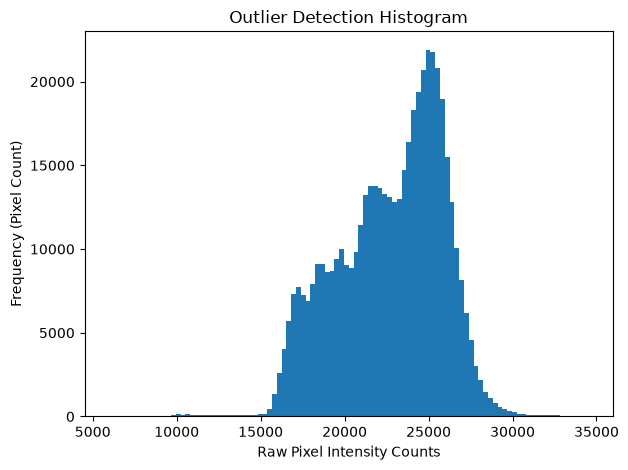

'Inferred: Presence of Outliters is not observed from the generated histogram.'

In [21]:
from matplotlib import pyplot as plt

plt.hist(data_array[0].ravel(), bins = 100)
plt.title("Outlier Detection Histogram")
plt.xlabel("Raw Pixel Intensity Counts")
plt.ylabel("Frequency (Pixel Count)")
plt.tight_layout()
plt.show()

'''Inferred: Presence of Outliters is not observed from the generated histogram.'''

In [ ]:
import numpy as np

# Outliters have not been found, hence proceeding with the Min-Max Normalization
data_array_norm = []

def min_max_norm(data_arr):
    min = data_arr.min()
    max = data_arr.max()
    if np.abs(min - max) == 0:
        return data_arr
    return (data_arr - min)/(max - min)

for data_arr_day in data_array:
    data_arr_day_norm = min_max_norm(data_arr=data_arr_day)
    data_arr_day_norm = np.array(data_arr_day_norm * 255, dtype=np.uint8)
    data_array_norm.append(data_arr_day_norm)

data_array_norm = np.array(data_array_norm)
print(data_array_norm)


[[[ 89  90  91 ... 170 167 167]
  [ 89  91  89 ... 169 159 167]
  [ 89  93  91 ... 177 172 170]
  ...
  [100 100 102 ... 158 159 158]
  [102 105 104 ... 162 165 160]
  [ 96 102 106 ... 158 163 159]]

 [[132 134 132 ... 161 159 155]
  [127 133 121 ... 158 162 157]
  [130 126 104 ... 152 157 165]
  ...
  [123 124 120 ... 176 166 171]
  [112 118 121 ... 166 171 168]
  [109 118 120 ... 164 153 161]]

 [[120 122 116 ... 102  96 113]
  [121 122 122 ... 108 102 107]
  [121 120 125 ... 110 108 115]
  ...
  [124 118 111 ... 112 113 113]
  [123 123 122 ... 111 116 111]
  [120 119 124 ... 112 115 114]]

 ...

 [[156 155 154 ... 103 104 104]
  [152 155 156 ... 104 100 107]
  [152 158 159 ... 106  99 103]
  ...
  [124  82  72 ...  54  52  55]
  [125  85  62 ...  54  53  56]
  [131 108  75 ...  54  55  53]]

 [[209 209 206 ...  78  77  74]
  [212 209 202 ...  79  78  80]
  [203 204 205 ...  80  79  74]
  ...
  [143 146 147 ...  29  31  27]
  [145 144 144 ...  28  27  28]
  [143 146 140 ...  30  29  

In [5]:
from skimage import measure

def region_stats(mask, min_area=15):
    labelled_regions = measure.label(mask)
    region_props = measure.regionprops(labelled_regions)

    # Handling Noise Filtering
    filtered_noise = [r for r in region_props if r.area > min_area]

    return {
        "count": len(filtered_noise),
        "areas": [r.area for r in filtered_noise],
        "centroids": [r.centroid for r in filtered_noise]
    }

Otsu's Threshold

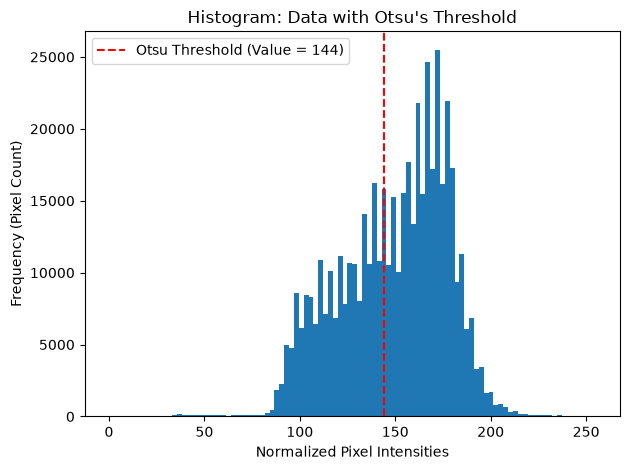

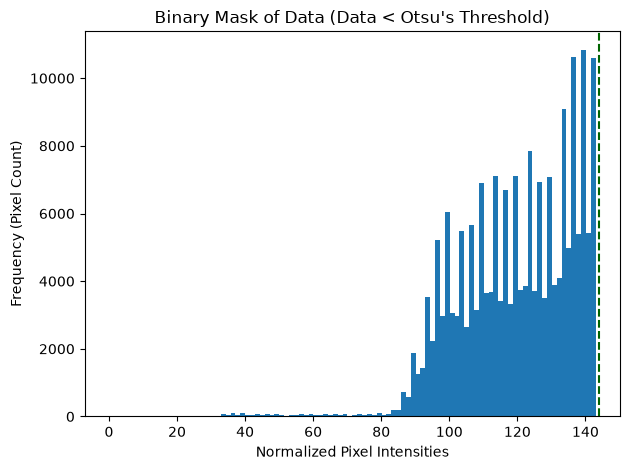

In [34]:
# Cell 7
from skimage.filters import threshold_otsu

data_sample1 = data_array_norm[0]

thresh1 = threshold_otsu(data_sample1)

plt.hist(data_sample1.ravel(), bins=100)
plt.axvline(thresh1, color="red", linestyle="dashed", label=f"Otsu Threshold (Value = {thresh1})")
plt.title("Histogram: Data with Otsu's Threshold")
plt.xlabel("Normalized Pixel Intensities")
plt.ylabel("Frequency (Pixel Count)")
plt.legend()
plt.tight_layout()
plt.show()

bin_mask = data_sample1 < thresh1
data_sample1_masked = data_sample1[bin_mask]

plt.hist(data_sample1_masked.ravel(), bins=100)
plt.axvline(thresh1, color="darkgreen", linestyle="dashed", label="Otsu Threshold Value")
plt.title("Binary Mask of Data (Data < Otsu's Threshold)")
plt.xlabel("Normalized Pixel Intensities")
plt.ylabel("Frequency (Pixel Count)")
plt.tight_layout()
plt.show()

In [7]:
from skimage.filters import threshold_otsu
# Implementing region_stats() for Otsu Threshold
otsu_val_dict = {}

for ind in range(len(data_array_norm)):
    data_sample_ind = data_array_norm[ind]
    thresh_val = threshold_otsu(data_sample_ind)

    bin_mask_otsu = data_sample_ind < thresh_val

    otsu_val_dict[ind] = region_stats(bin_mask_otsu)
    for key, val in otsu_val_dict.items():
        print(f"Day {key}: {val['count']} regions, Areas={val['areas']}")

Day 0: 52 regions, Areas=[np.float64(180602.0), np.float64(17.0), np.float64(167.0), np.float64(23.0), np.float64(17.0), np.float64(25.0), np.float64(23.0), np.float64(19.0), np.float64(21.0), np.float64(29.0), np.float64(35.0), np.float64(18.0), np.float64(92.0), np.float64(20.0), np.float64(18.0), np.float64(16.0), np.float64(316.0), np.float64(23.0), np.float64(16.0), np.float64(20.0), np.float64(16.0), np.float64(75.0), np.float64(686.0), np.float64(23.0), np.float64(41.0), np.float64(18.0), np.float64(39.0), np.float64(22.0), np.float64(175.0), np.float64(40.0), np.float64(18.0), np.float64(24.0), np.float64(16.0), np.float64(24.0), np.float64(24.0), np.float64(21.0), np.float64(33.0), np.float64(711.0), np.float64(5178.0), np.float64(79.0), np.float64(25.0), np.float64(567.0), np.float64(119.0), np.float64(19.0), np.float64(27.0), np.float64(57.0), np.float64(175.0), np.float64(44.0), np.float64(17.0), np.float64(356.0), np.float64(18.0), np.float64(41.0)]
Day 0: 52 regions, Area

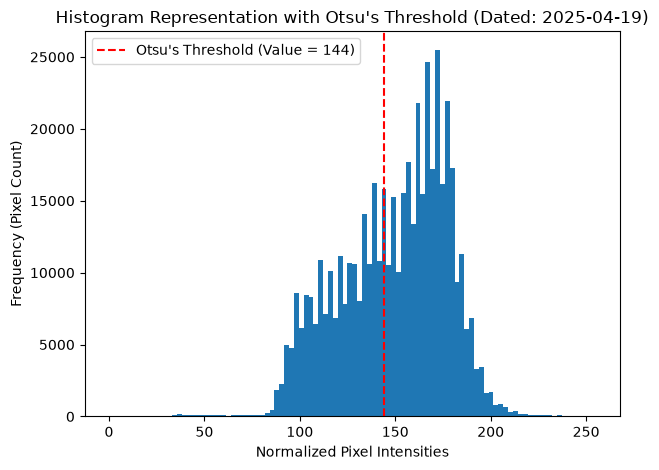

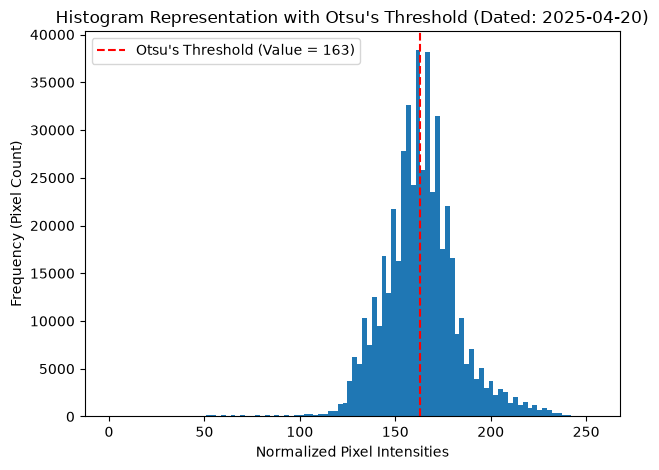

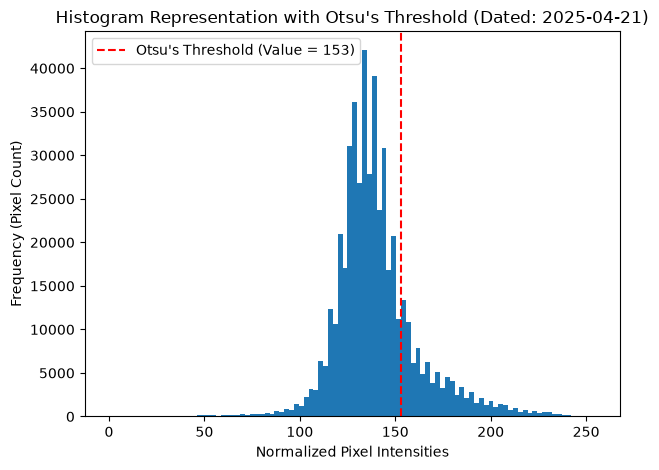

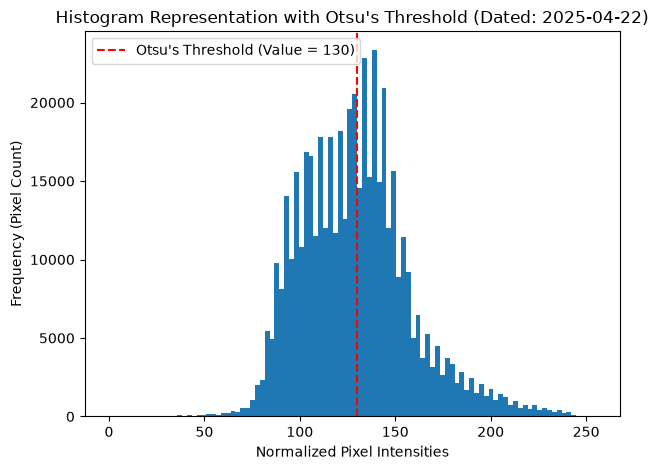

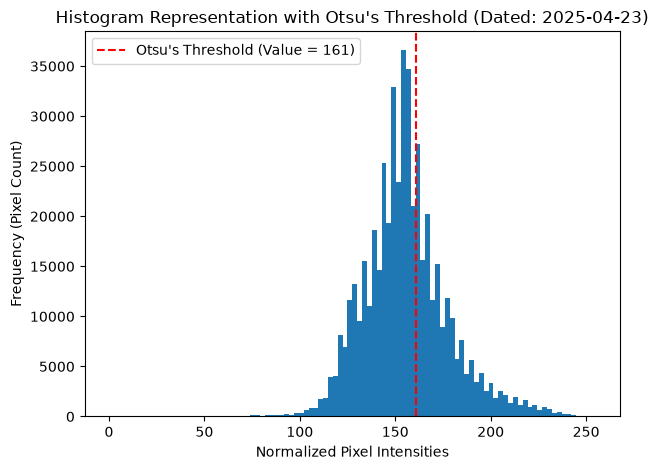

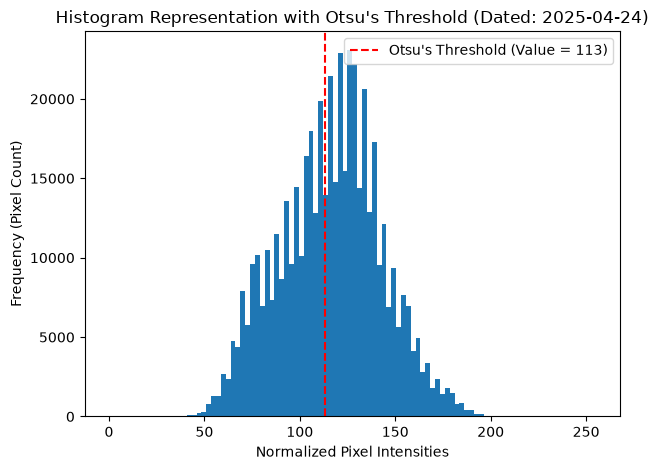

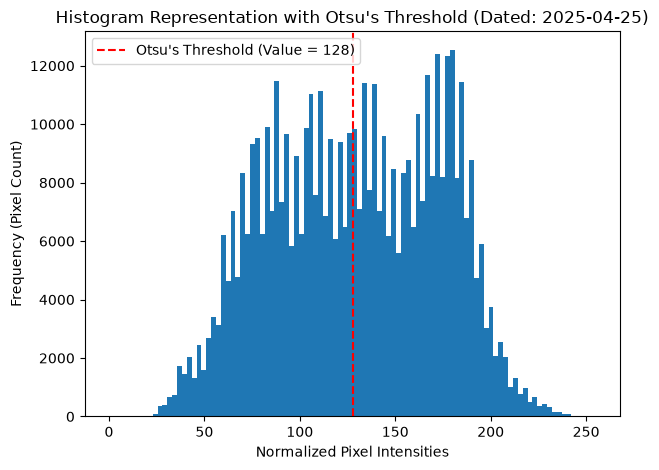

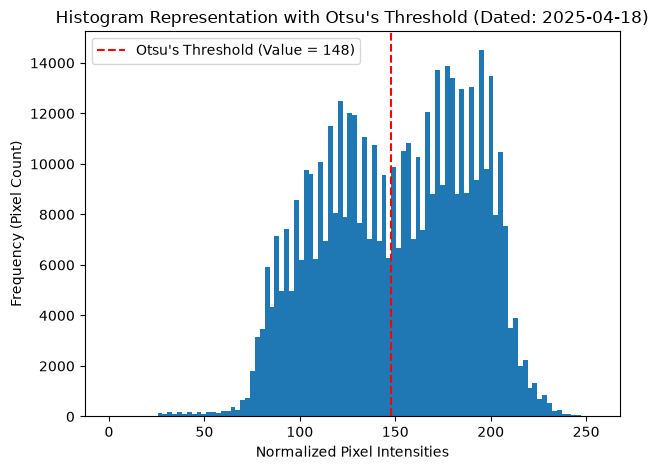

In [35]:
for ind, date in zip(range(len(data_array_norm)), date_array):
    data_sample_ind = data_array_norm[ind]
    thresh_val = threshold_otsu(data_sample_ind)

    plt.hist(data_array_norm[ind].ravel(), bins=100)
    plt.axvline(thresh_val, color="red", linestyle="dashed", label=f"Otsu's Threshold (Value = {thresh_val})")
    plt.title(f"Histogram Representation with Otsu's Threshold (Dated: {date})")
    plt.xlabel("Normalized Pixel Intensities")
    plt.ylabel("Frequency (Pixel Count)")
    plt.tight_layout()
    plt.legend()
    plt.show()


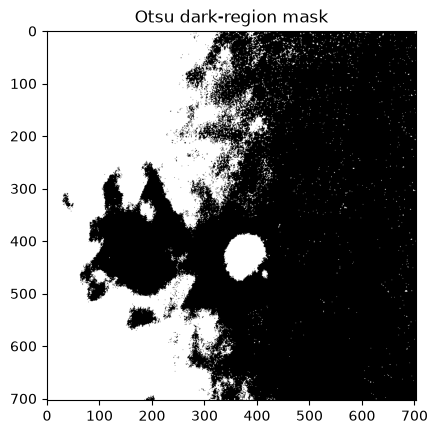

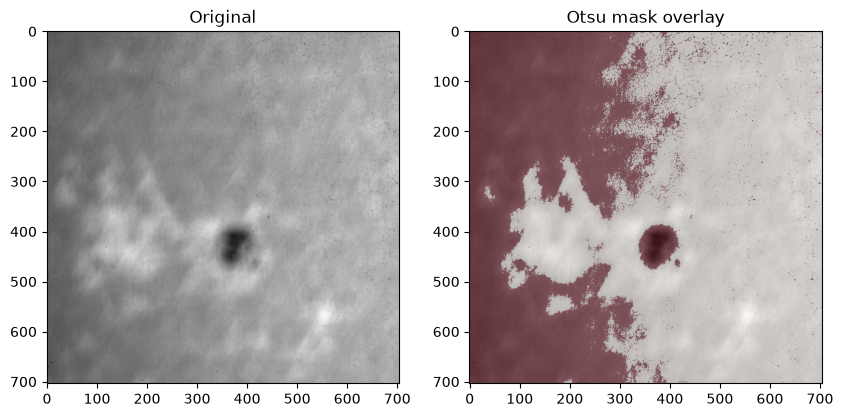

In [9]:
plt.imshow(bin_mask, cmap='gray')
plt.title("Otsu dark-region mask")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10,5))
axes[0].imshow(data_sample1, cmap='gray')
axes[0].set_title("Original")
axes[1].imshow(data_sample1, cmap='gray')
axes[1].imshow(bin_mask, cmap='Reds', alpha=0.4)
axes[1].set_title("Otsu mask overlay")
plt.show()

The sunspot itself is captured (that solid dark blob around x=380, y=400) — but Otsu also swept up a huge portion of the entire left half of the image as "dark region," clearly following the general brightness gradient across the frame rather than isolating the compact sunspot feature. 

Adaptive Thresholding

In [10]:
import cv2

adp_thresh_meanc = {}
adp_thresh_gauss = {}

for ind in range(len(data_array_norm)):
    data_sample_adpthresh = data_array_norm[ind]

    thresh_adaptive_mean_c = cv2.adaptiveThreshold(
        data_sample_adpthresh, 255, 
        cv2.ADAPTIVE_THRESH_MEAN_C, 
        cv2.THRESH_BINARY, 
        25, 10
    )

    thresh_adaptive_gaussian = cv2.adaptiveThreshold(
        data_sample_adpthresh, 255, 
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
        cv2.THRESH_BINARY, 
        51, 10
    )

    # For dark regions/pixels ; Verifying with 0
    mask_adapt_thresh_mean_c = thresh_adaptive_mean_c == 0 
    mask_adapt_thresh_gauss = thresh_adaptive_gaussian == 0

    adp_thresh_meanc[ind] = region_stats(mask_adapt_thresh_mean_c)
    adp_thresh_gauss[ind] = region_stats(mask_adapt_thresh_gauss)

    for key, val in adp_thresh_meanc.items():
            print(f"Day {key}: {val['count']} regions, Areas={val['areas']}")
    for key, val in adp_thresh_gauss.items():
                print(f"Day {key}: {val['count']} regions, Areas={val['areas']}")
    

Day 0: 44 regions, Areas=[np.float64(20.0), np.float64(16.0), np.float64(16.0), np.float64(18.0), np.float64(17.0), np.float64(25.0), np.float64(17.0), np.float64(25.0), np.float64(19.0), np.float64(33.0), np.float64(27.0), np.float64(16.0), np.float64(17.0), np.float64(32.0), np.float64(27.0), np.float64(30.0), np.float64(25.0), np.float64(25.0), np.float64(18.0), np.float64(41.0), np.float64(17.0), np.float64(40.0), np.float64(17.0), np.float64(836.0), np.float64(79.0), np.float64(22.0), np.float64(74.0), np.float64(41.0), np.float64(31.0), np.float64(71.0), np.float64(552.0), np.float64(25.0), np.float64(19.0), np.float64(34.0), np.float64(192.0), np.float64(61.0), np.float64(29.0), np.float64(24.0), np.float64(20.0), np.float64(34.0), np.float64(19.0), np.float64(21.0), np.float64(26.0), np.float64(20.0)]
Day 0: 39 regions, Areas=[np.float64(16.0), np.float64(17.0), np.float64(25.0), np.float64(25.0), np.float64(30.0), np.float64(17.0), np.float64(27.0), np.float64(16.0), np.float6

Text(0.5, 1.0, 'Adaptive Threshold Applied (Gaussian)')

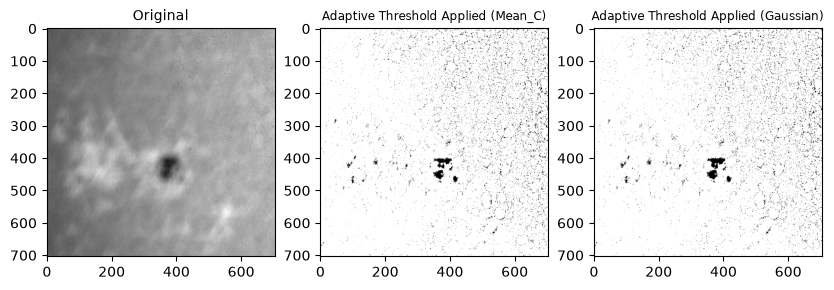

In [11]:
#Plotting

fig, ax = plt.subplots(1, 3, figsize=(10, 5))

data_sample1 = data_array_norm[0]

thresh_adaptive_mean_c_0 = cv2.adaptiveThreshold(
    data_sample1, 255, 
    cv2.ADAPTIVE_THRESH_MEAN_C, 
    cv2.THRESH_BINARY, 
    25, 10
)

thresh_adaptive_gaussian_0 = cv2.adaptiveThreshold(
    data_sample1, 255, 
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY, 
    51, 10
)

mask_adapt_thresh_gauss_0 = thresh_adaptive_gaussian_0 == 0
mask_adapt_thresh_mean_c_0 = thresh_adaptive_mean_c_0 == 0

ax[0].imshow(data_sample1, cmap="grey")
ax[0].set_title("Original", fontsize=10)

ax[1].imshow(thresh_adaptive_mean_c_0, cmap="grey")
ax[1].set_title("Adaptive Threshold Applied (Mean_C)", fontsize=8.5)

ax[2].imshow(thresh_adaptive_gaussian_0, cmap="grey")
ax[2].set_title("Adaptive Threshold Applied (Gaussian)", fontsize=8.5)

K-Means Clustering

In [12]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA

In [13]:
# Implementing the region_stats() for K-Means Clustering
k_means_dict = {}

for ind in range(len(data_array_norm)):
    pixel_curr = data_array_norm[ind].reshape(-1, 1)

    kmeans_set = KMeans(n_clusters=2, max_iter=300, tol=0.001, algorithm="lloyd")
    kmeans_set_fit = kmeans_set.fit(X=pixel_curr)

    kmeans_labels = kmeans_set_fit.labels_
    label_img = kmeans_labels.reshape(data_array_norm[ind].shape)

    centroids = kmeans_set.cluster_centers_
    dark_clus = np.argmin(centroids)

    k_mask = label_img == dark_clus

    k_means_dict[ind] = region_stats(mask=k_mask)

    for key, val in k_means_dict.items():
        print(f"Day {key}: {val['count']} regions, Area: {val['areas']}")

Day 0: 43 regions, Area: [np.float64(191415.0), np.float64(26.0), np.float64(291.0), np.float64(20.0), np.float64(23.0), np.float64(22.0), np.float64(102.0), np.float64(23.0), np.float64(83.0), np.float64(246.0), np.float64(26.0), np.float64(35.0), np.float64(16.0), np.float64(27.0), np.float64(21.0), np.float64(21.0), np.float64(20.0), np.float64(20.0), np.float64(16.0), np.float64(17.0), np.float64(16.0), np.float64(21.0), np.float64(1330.0), np.float64(17.0), np.float64(17.0), np.float64(17.0), np.float64(41.0), np.float64(185.0), np.float64(90.0), np.float64(21.0), np.float64(16.0), np.float64(5359.0), np.float64(16.0), np.float64(168.0), np.float64(50.0), np.float64(142.0), np.float64(41.0), np.float64(29.0), np.float64(70.0), np.float64(579.0), np.float64(21.0), np.float64(18.0), np.float64(17.0)]
Day 0: 43 regions, Area: [np.float64(191415.0), np.float64(26.0), np.float64(291.0), np.float64(20.0), np.float64(23.0), np.float64(22.0), np.float64(102.0), np.float64(23.0), np.float6

[0 0 0 ... 1 1 1]


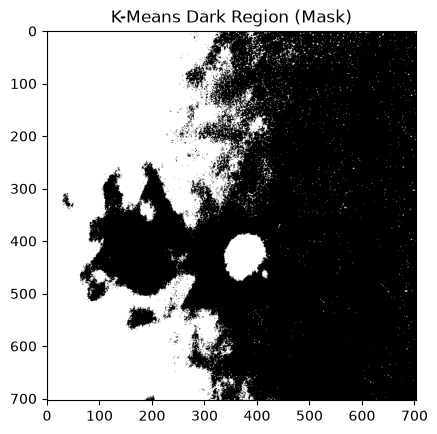

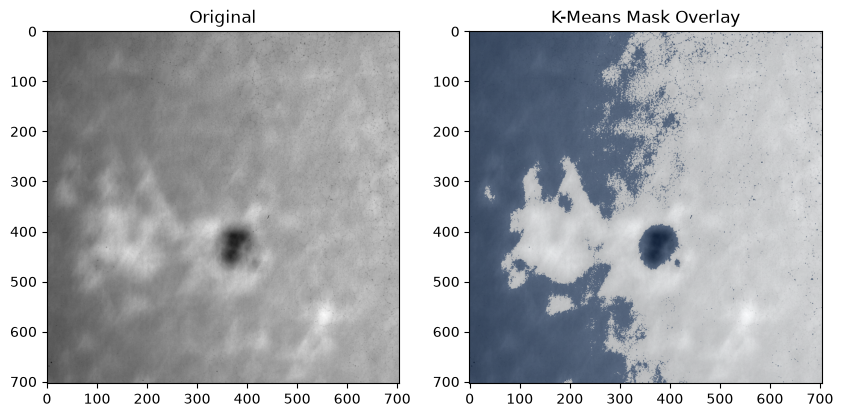

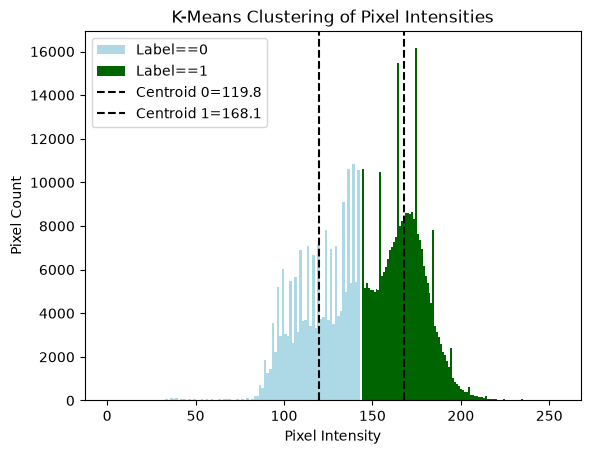

In [14]:
pixels = data_array_norm[0].reshape(-1, 1)

kmeans_data_array_set = KMeans(n_clusters=2, max_iter=300, tol=0.001, algorithm="lloyd")
kmeans_data_array_set_fit = kmeans_data_array_set.fit(X=pixels)

kmeans_data_array_labels = kmeans_data_array_set_fit.labels_
print(kmeans_data_array_labels)

centroids_list = kmeans_data_array_set.cluster_centers_

label_image = kmeans_data_array_labels.reshape(data_array_norm[0].shape)

dark_cluster = np.argmin(centroids_list)

kmeans_mask = label_image==dark_cluster

plt.imshow(kmeans_mask, cmap='gray')
plt.title("K-Means Dark Region (Mask)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10,5))
axes[0].imshow(data_array_norm[0], cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(data_array_norm[0], cmap="gray")
axes[1].imshow(kmeans_mask, cmap="Blues", alpha=0.4)
axes[1].set_title("K-Means Mask Overlay")
plt.show()

plt.hist(pixels[kmeans_data_array_labels==0], bins=100, color="lightblue", label="Label==0")
plt.hist(pixels[kmeans_data_array_labels==1], bins=100, color="darkgreen", label="Label==1")

for i, c in enumerate(centroids_list.ravel()):
    plt.axvline(c, color="black", linestyle="dashed", label=f"Centroid {i}={c:.1f}")

plt.title("K-Means Clustering of Pixel Intensities")
plt.xlabel("Pixel Intensity")
plt.ylabel("Pixel Count")
plt.legend()
plt.show()




Comparitive plot of Otsu v/s Adaptive Thresh v/s K-Means (Considering Data_Sample[0])

Text(0.5, 1.0, 'K-Means Mask Overlay')

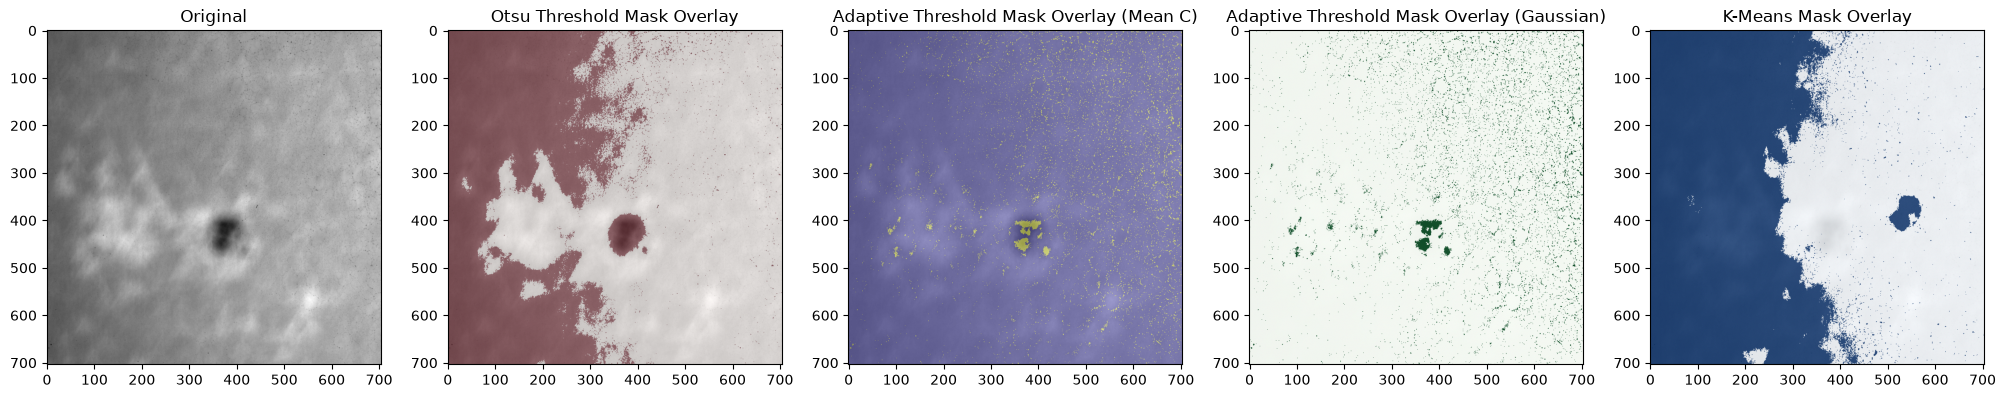

In [15]:
# Plotting the Overlay Mask images

fig, ax = plt.subplots(1, 5, figsize = (25,6))

ax[0].set_title("Original")
ax[0].imshow(data_sample1, cmap="gray")

ax[1].imshow(data_sample1, cmap="gray", alpha = 0.8)
ax[1].imshow(bin_mask, cmap="Reds", alpha = 0.4)
ax[1].set_title("Otsu Threshold Mask Overlay")

ax[2].imshow(data_sample1, cmap="gray", alpha=0.7)
ax[2].imshow(mask_adapt_thresh_mean_c_0, cmap="plasma", alpha=0.4)
ax[2].set_title("Adaptive Threshold Mask Overlay (Mean C)")

ax[3].imshow(data_sample1, cmap="gray", alpha=0.4)
ax[3].imshow(mask_adapt_thresh_gauss_0, cmap="Greens", alpha=0.9)
ax[3].set_title("Adaptive Threshold Mask Overlay (Gaussian)")

ax[4].imshow(data_sample1, cmap="gray", alpha=0.8)
ax[4].imshow(k_mask, cmap="Blues", alpha=0.8)
ax[4].set_title("K-Means Mask Overlay")



### VALIDATION ###

In [16]:
from sunpy.net import Fido, attrs as a

results = Fido.search(a.Time("2025-04-18", "2025-04-25"), a.Instrument.soon)
print(results)

srs_files = Fido.fetch(results)

Results from 1 Provider:

8 Results from the SRSClient:

       Start Time               End Time        Instrument Physobs Source Provider
----------------------- ----------------------- ---------- ------- ------ --------
2025-04-18 00:00:00.000 2025-04-18 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-19 00:00:00.000 2025-04-19 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-20 00:00:00.000 2025-04-20 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-21 00:00:00.000 2025-04-21 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-22 00:00:00.000 2025-04-22 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-23 00:00:00.000 2025-04-23 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-24 00:00:00.000 2025-04-24 23:59:59.999       SOON     SRS   SWPC     NOAA
2025-04-25 00:00:00.000 2025-04-25 23:59:59.999       SOON     SRS   SWPC     NOAA




Files Downloaded:   0%|          | 0/8 [00:00<?, ?file/s]

20250420SRS.txt:   0%|          | 0.00/917 [00:00<?, ?B/s]

20250421SRS.txt:   0%|          | 0.00/903 [00:00<?, ?B/s]

20250422SRS.txt:   0%|          | 0.00/941 [00:00<?, ?B/s]

20250419SRS.txt:   0%|          | 0.00/957 [00:00<?, ?B/s]

20250423SRS.txt:   0%|          | 0.00/996 [00:00<?, ?B/s]

In [17]:
print(srs_files.errors)

[]


**Note:** SunPy.Fido had a successful fetch at certain times, but also reported some errors in fetching due to Error: 503 Service Unavailable. The Results were derived from the iteration when it had a successful fetch.

In [ ]:
import astropy.units as u
import numpy as np
import pandas as pd
import re


def parse_srs_location(loc_str):                                # UDF to get latitude and longitude from the SRS file
    match = re.match(r'([NS])(\d+)([EW])(\d+)', loc_str)
    if not match:
        return None
    ns, lat_val, ew, lon_val = match.groups()
    lat = float(lat_val) if ns == 'N' else -float(lat_val)
    lon = float(lon_val) if ew == 'E' else -float(lon_val)
    return lat, lon

def find_closest_region(srs_path, target_lat, target_lon):      # UDF to read the SRS file and find closest/best region
    with open(srs_path, 'r') as f:
        lines = f.readlines()
    in_section_1 = False
    best_region, best_dist = None, float('inf')
    for line in lines:
        if line.startswith("I."):                               # Boolean operations performed while reading the file w.r.t section number
            in_section_1 = True
            continue
        if line.startswith("IA.") or line.startswith("II."):
            in_section_1 = False
        if in_section_1 and re.match(r'^\d{4}\s', line):
            parts = line.split()
            nmbr, loc_str = parts[0], parts[1]
            parsed = parse_srs_location(loc_str)
            if parsed is None:
                continue
            lat, lon = parsed
            dist = ((lat - target_lat)**2 + (lon - target_lon)**2) ** 0.5               # Euclidean Distance computation
            if dist < best_dist:                                                        # Algorithm to get best_dist and region_number
                best_dist = dist
                best_region = nmbr
    return best_region, best_dist

reference_idx = 3                                               # reference_idx chosen as 3. Active region best positioned near center of solar disk
reference_map = suit_bb01_files[reference_idx]
hgs_center = reference_map.center.transform_to("heliographic_stonyhurst")

tracked_region, id_dist = find_closest_region(
    srs_files[reference_idx], hgs_center.lat.value, hgs_center.lon.value
)
print(f"Tracked region: {tracked_region} (id match distance: {id_dist:.2f} deg)")


def get_region_data(srs_path, region_number):       # UDF to get additional attributes from SRS file --> loc_str, area
    with open(srs_path, 'r') as f:
        lines = f.readlines()
    in_section_1 = False
    for line in lines:
        if line.startswith("I."):
            in_section_1 = True
            continue
        if line.startswith("IA.") or line.startswith("II."):
            in_section_1 = False
        if in_section_1 and line.startswith(region_number):
            parts = line.split()
            loc_str, area = parts[1], float(parts[3])
            lat, lon = parse_srs_location(loc_str)
            return {"lat": lat, "lon": lon, "area": area}
    return None  # Region missing on respective day

srs_ground_truth = {}                   # Baseline. Fetched from the NOAA catalogue
for ind in range(len(suit_bb01_files)):
    srs_ground_truth[ind] = get_region_data(srs_files[ind], tracked_region)

for day, gt in srs_ground_truth.items():
    print(f"Day {day}: {gt}")


# ============================================================
# STEP 3: Convert detected centroids (pixel) -> heliographic
# ============================================================

def centroids_to_heliographic(centroids, smap):
    """centroids: list of (row, col) from regionprops"""
    converted = []
    for row, col in centroids:
        world = smap.pixel_to_world(col * u.pix, row * u.pix)
        hgs = world.transform_to("heliographic_stonyhurst")         # "heliographic_stonyhurst": coordinate system (specification of location) for the Sun
        converted.append((hgs.lat.value, hgs.lon.value))
    return converted


TOLERANCE_DEG = 5.0  

def evaluate_method(results_dict, method_name):
    hit_days = 0
    valid_days = 0
    localization_errors = []
    fp_counts = []
    fp_areas = []

    for day, res in results_dict.items():
        gt = srs_ground_truth.get(day)
        if gt is None:
            continue  # No validation for the respective day if ground truth is absent
        valid_days += 1

        smap = suit_bb01_files[day]
        hgs_centroids = centroids_to_heliographic(res["centroids"], smap)

        distances = [                   # Using the Euclidean Distance formula
            ((lat - gt["lat"])**2 + (lon - gt["lon"])**2) ** 0.5
            for lat, lon in hgs_centroids
        ]

        matched_idx = None
        if distances:
            min_dist = min(distances)
            if min_dist <= TOLERANCE_DEG:           # If min_distance <= TOLERANCE_DEG, counted as a hit
                matched_idx = distances.index(min_dist)

        if matched_idx is not None:
            hit_days += 1
            localization_errors.append(distances[matched_idx])
            fp_count = len(res["centroids"]) - 1
            fp_area = sum(a for i, a in enumerate(res["areas"]) if i != matched_idx)
        else:
            fp_count = len(res["centroids"])
            fp_area = sum(res["areas"])

        fp_counts.append(fp_count)
        fp_areas.append(fp_area)

    # METRIC FORMULAE
    recall = hit_days / valid_days if valid_days else 0
    mean_loc_error = np.mean(localization_errors) if localization_errors else None
    mean_fp_count = np.mean(fp_counts) if fp_counts else None
    mean_fp_area = np.mean(fp_areas) if fp_areas else None

    return {
        "Method": method_name,
        "Recall": recall,
        "Mean Localization Error (deg)": mean_loc_error,
        "Mean False Positive Count": mean_fp_count,
        "Mean False Positive Area (px)": mean_fp_area
    }


summary = [
    evaluate_method(otsu_val_dict, "Otsu"),
    evaluate_method(adp_thresh_meanc, "Adaptive (Mean C)"),
    evaluate_method(adp_thresh_gauss, "Adaptive (Gaussian)"),
    evaluate_method(k_means_dict, "K-Means"),
]

summary_df = pd.DataFrame(summary)          # Creating the summary data frame using Pandas
summary_df

Tracked region: 4066 (id match distance: 9.89 deg)
Day 0: {'lat': -5.0, 'lon': 49.0, 'area': 40.0}
Day 1: {'lat': -4.0, 'lon': 33.0, 'area': 30.0}
Day 2: {'lat': -4.0, 'lon': 21.0, 'area': 20.0}
Day 3: {'lat': -4.0, 'lon': 8.0, 'area': 20.0}
Day 4: {'lat': -5.0, 'lon': -4.0, 'area': 10.0}
Day 5: None
Day 6: None
Day 7: {'lat': -5.0, 'lon': -44.0, 'area': 10.0}


,Method,Recall,Mean Localization Error (deg),Mean False Positive Count,Mean False Positive Area (px)
0,Otsu,0.500000,3.003408,109.500000,265867.0
1,Adaptive (Mean C),0.666667,1.225297,250.833333,8534.0
2,Adaptive (Gaussian),0.666667,1.224360,237.500000,8361.5
3,K-Means,0.500000,2.765825,104.333333,273171.5


## RESULT SUMMARY ##

Upon a conclusive study of the output obtained, a Result summary has been inferred, and elaborated as follows:

* **Recall**: Adaptive (0.667) showed a better recall rate than the Otsu and K-Means models (tied at 0.5 each)
* **Mean Localization Error (deg)**: Adaptive is more precise than the Otsu and K-Means models by a scale factor of about 2.5
* **Mean False Positive Count**: Otsu and K-Means was found to have fewer false positive counts compared to the Adaptive Thresholding.
* **Mean False Positive Area**: Otsu and K-Means was found to misclassify the active regions (dumped over 265,000 - 278,000 px) while    Adaptive showed a better performance by staying around 8,300 - 8,500 px.

From the results obtained, it can be inferred in general that the **Adaptive Thresholding** model performed better with respect to the metrics used.

